### Notebook 5 — Final Evaluation of the Six Scenarios

> Computes, for every scenario, the AUROC, AUPRC and the threshold-based metrics (recall, specificity, precision, F1) on the held-out real test sets with **patient-level cluster-bootstrap confidence intervals**, compares each scenario with the baseline through a **paired bootstrap**, and breaks the results down by view position and by the other-disease labels. It also summarises the real-versus-synthetic shortcut diagnostic.

**Inputs to attach**: (1) the test set, either the output of Notebook 2 (`real_test_full.csv`, `real_test_clean.csv`) or the image cache of Notebook 4a (`test_full_index.csv`, which carries the same columns plus the clean flag); (2) the output(s) of Notebook 4b (`preds/*.csv.gz` and `runs_summary.csv`). Attach every 4b output you have (for example the main run and the ablation run). **No GPU is needed.**

**Definitions**

* **AUROC** (primary metric) and **AUPRC** (average precision) are threshold-free.
* **Recall** (sensitivity), **specificity**, **precision** (positive predictive value) and **F1** use the decision threshold chosen on the *real validation set* (Youden index) in Notebook 4b; nothing is tuned on the test set.
* Precision depends on prevalence, which is low in the test sets (pneumonia is 5.3% of the clean and 2.2% of the full version), so its absolute values are low for every scenario; compare it between scenarios, and read it together with AUPRC.
* **Clean** = pneumonia vs No Finding; **full** = adds the other-disease images as hard negatives.

**Confidence intervals**: images from the same patient are resampled together (patient-level cluster bootstrap, 2.5-97.5 percentiles). Each scenario was trained with several seeds; the reported value is the mean over seeds, and in every bootstrap replicate the same resampled test set is used for all scenarios, so differences between scenarios are **paired**. The interval therefore reflects test-set sampling uncertainty; the variation between training seeds is shown separately.

### 1. Configuration and Input Discovery

In [1]:
import os, re, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve
warnings.filterwarnings('ignore')

N_BOOT, SEED = 2000, 42
INPUT_ROOT, OUT = '/kaggle/input', Path('/kaggle/working/eval'); OUT.mkdir(parents=True, exist_ok=True)
REF = 'S1'                                           # baseline scenario for the paired comparisons

NAMES = {'S1': 'Real 5K (baseline)', 'S2': 'DC-GAN only', 'S3': 'Real 5K + DC-GAN pos.', 'S4': 'RoentGen-v2 only', 'S5': 'Real 5K + RoentGen pos.', 'S6': 'Real 10K',
         'S3-bal': 'S3 + 2,500 DC-GAN neg.', 'S5-bal': 'S5 + 2,500 RoentGen neg.', 'S3-dose1000': 'S3 with 1,000 syn. pos.', 'S3-dose2500': 'S3 with 2,500 syn. pos.',
         'S5-dose1000': 'S5 with 1,000 syn. pos.', 'S5-dose2500': 'S5 with 2,500 syn. pos.'}
ORDER = list(NAMES)
COLORS = {'S1': '#2a78d6', 'S2': '#eb6834', 'S3': '#1baf7a', 'S4': '#eda100', 'S5': '#e87ba4', 'S6': '#008300', 'S3-bal': '#4a3aa7', 'S5-bal': '#e34948',
          'S3-dose1000': '#7fd1b0', 'S3-dose2500': '#0f7a52', 'S5-dose1000': '#f3b3cd', 'S5-dose2500': '#b0457a'}
nm = lambda s: NAMES.get(s, s)

ALL = []
for cur, dirs, files in os.walk(INPUT_ROOT):
    dirs[:] = [d for d in dirs if d != 'images']
    ALL += [os.path.join(cur, f) for f in files]
h = [p for p in ALL if os.path.basename(p) == 'real_test_full.csv']; h2 = [p for p in ALL if os.path.basename(p) == 'test_full_index.csv']
assert h or h2, 'test set not found: attach the output of Notebook 2 (real_test_full.csv) or the image cache of Notebook 4a (test_full_index.csv)'
SPLITS_DIR = os.path.dirname(h[0]) if h else None; TEST_INDEX = h2[0] if h2 else None
PRED_FILES = sorted(p for p in ALL if re.search(r'_seed\d+\.csv\.gz$', p)); assert PRED_FILES, 'no prediction files found: attach the output(s) of Notebook 4b'
SUMMARIES = [p for p in ALL if os.path.basename(p) == 'runs_summary.csv']; assert SUMMARIES, 'runs_summary.csv not found: attach the output(s) of Notebook 4b'
print('test set from:', f'{SPLITS_DIR}/real_test_full.csv' if SPLITS_DIR else TEST_INDEX); print(f'{len(PRED_FILES)} prediction files | {len(SUMMARIES)} summary file(s)')

test set from: /kaggle/input/datasets/anafarr/chestxray-cache-224/cache/test_full_index.csv
36 prediction files | 3 summary file(s)


### 2. Test Sets and Predictions

The test table has every test image with its patient, label, view position and finding labels; the clean version is the subset listed in `real_test_clean.csv` (or the `clean` column of the Notebook 4a index).

In [2]:
if SPLITS_DIR:
    test = pd.read_csv(f'{SPLITS_DIR}/real_test_full.csv'); test['clean'] = test['image'].isin(set(pd.read_csv(f'{SPLITS_DIR}/real_test_clean.csv')['image']))
else:
    test = pd.read_csv(TEST_INDEX); assert 'clean' in test.columns                       # index written by Notebook 4a (same rows and columns, plus the clean flag)
assert set(test.label.unique()) <= {0, 1}
pos_of = test.set_index('image').index
print(f"test_full: {len(test):,} images, {test['Patient ID'].nunique():,} patients, {int(test.label.sum())} pneumonia ({100 * test.label.mean():.1f}%) | "
      f"test_clean: {int(test.clean.sum()):,} images, {int(test.label[test.clean].sum())} pneumonia ({100 * test.label[test.clean].mean():.1f}%)")

summ = pd.concat([pd.read_csv(p) for p in SUMMARIES], ignore_index=True).drop_duplicates(['scenario', 'seed'], keep='last').set_index(['scenario', 'seed'])
RUNS = {}                                                          # (scenario, seed) -> dict(p=test probabilities, thr=threshold, syn={generator: probabilities of synthetic No Finding images})
for f in PRED_FILES:
    scn, seed = re.search(r'([^/]+)_seed(\d+)\.csv\.gz$', f).groups(); seed = int(seed)
    if (scn, seed) not in summ.index: print('no summary row for', scn, seed, '-> skipped'); continue
    d = pd.read_csv(f); t = d[d.split == 'test'].set_index('image')['prob']
    assert len(t) == len(test), f'{f}: {len(t)} test predictions instead of {len(test)}'
    RUNS[(scn, seed)] = dict(p=t.reindex(test.image).values.astype(np.float64), thr=float(summ.loc[(scn, seed), 'threshold']),
                             syn={s.replace('synneg_', ''): d[d.split == s]['prob'].values for s in d.split.unique() if s.startswith('synneg_')}, file=f)
SCN = sorted({k[0] for k in RUNS}, key=lambda s: (ORDER.index(s) if s in ORDER else 99, s)); SEEDS = {s: sorted(k[1] for k in RUNS if k[0] == s) for s in SCN}
assert REF in SCN, f'baseline {REF} not found among {SCN}'
print({s: SEEDS[s] for s in SCN})

test_full: 25,592 images, 2,797 patients, 554 pneumonia (2.2%) | test_clean: 10,415 images, 554 pneumonia (5.3%)
{'S1': [0, 1, 2], 'S2': [0, 1, 2], 'S3': [0, 1, 2], 'S4': [0, 1, 2], 'S5': [0, 1, 2], 'S6': [0, 1, 2], 'S3-bal': [0, 1, 2], 'S5-bal': [0, 1, 2], 'S3-dose1000': [0, 1, 2], 'S3-dose2500': [0, 1, 2], 'S5-dose1000': [0, 1, 2], 'S5-dose2500': [0, 1, 2]}


### 3. Metrics and Cluster Bootstrap

All metrics are computed with image weights, so that a bootstrap replicate is just a vector of weights (the number of times each patient was drawn). The weighted AUROC and AUPRC handle tied scores exactly as `sklearn` does (checked below).

In [3]:
METRICS = ['auroc', 'auprc', 'recall', 'specificity', 'precision', 'f1']

def make_subset(mask, B, rng):
    idx = np.where(mask)[0]; codes = pd.factorize(test['Patient ID'].values[idx])[0]; P = codes.max() + 1
    return dict(idx=idx, codes=codes, y=test.label.values[idx].astype(float), counts=rng.multinomial(P, np.full(P, 1 / P), size=B).astype(np.int32))

def _div(a, b): return np.divide(a, b, out=np.zeros_like(a, dtype=float), where=b > 0)

def run_metrics(p_all, thr, S, extra=None, chunk=200):
    """Point estimate and bootstrap replicates of every metric for one run on one subset. extra: optional (N x k) matrices (in the original subset order) to be weight-summed."""
    p, y = p_all[S['idx']], S['y']; order = np.argsort(p, kind='stable'); p_s, y_s, c_s = p[order], y[order], S['codes'][order]; N = len(p_s)
    starts = np.r_[0, np.flatnonzero(np.diff(p_s)) + 1]; starts_d = np.r_[0, np.flatnonzero(np.diff(p_s[::-1])) + 1]; ends_d = np.r_[starts_d[1:], N] - 1
    pred = p_s >= thr; ind = np.stack([y_s * pred, (1 - y_s) * pred, y_s * ~pred, (1 - y_s) * ~pred], 1)       # TP, FP, FN, TN
    ex = [e[order] for e in extra] if extra else []
    def core(W):
        b = len(W); wp, wn = W * y_s, W * (1 - y_s); Wp, Wn = wp.sum(1), wn.sum(1)
        neg_before = np.concatenate([np.zeros((b, 1)), np.cumsum(wn, 1)], 1)[:, starts]
        auroc = (np.add.reduceat(wp, starts, 1) * (neg_before + 0.5 * np.add.reduceat(wn, starts, 1))).sum(1) / (Wp * Wn)
        wpd, wd = wp[:, ::-1], W[:, ::-1]; cwp, cw = np.cumsum(wpd, 1)[:, ends_d], np.cumsum(wd, 1)[:, ends_d]
        auprc = (np.add.reduceat(wpd, starts_d, 1) * _div(cwp, cw)).sum(1) / Wp
        TP, FP, FN, TN = (W @ ind).T
        return dict(auroc=auroc, auprc=auprc, recall=_div(TP, TP + FN), specificity=_div(TN, TN + FP), precision=_div(TP, TP + FP), f1=_div(2 * TP, 2 * TP + FP + FN)), [W @ e for e in ex]
    pt, pt_ex = core(np.ones((1, N))); res_b, ex_b = [], []
    for i in range(0, len(S['counts']), chunk):
        r, e = core(S['counts'][i:i + chunk][:, c_s].astype(float)); res_b.append(r); ex_b.append(e)
    boot = {k: np.concatenate([r[k] for r in res_b]) for k in METRICS}
    return {k: float(pt[k][0]) for k in METRICS}, boot, ([np.concatenate([e[j] for e in ex_b]) for j in range(len(ex))], [e[0] for e in pt_ex]) if ex else None

# ---- check against sklearn on the point estimates (unweighted) ----
from sklearn.metrics import average_precision_score
_k = (SCN[0], SEEDS[SCN[0]][0]); _S = make_subset(test.clean.values, 20, np.random.default_rng(0)); _pt, _, _ = run_metrics(RUNS[_k]['p'], RUNS[_k]['thr'], _S)
_p, _y = RUNS[_k]['p'][_S['idx']], _S['y']
assert abs(_pt['auroc'] - roc_auc_score(_y, _p)) < 1e-9 and abs(_pt['auprc'] - average_precision_score(_y, _p)) < 1e-9, 'metric check failed'
print('weighted AUROC / AUPRC agree with sklearn:', round(_pt['auroc'], 4), round(_pt['auprc'], 4))

weighted AUROC / AUPRC agree with sklearn: 0.7243 0.1091


### 4. Run the Evaluation

Subsets: `clean`, `full` and each by view position (AP/PA). The same bootstrap samples (patients) are used for every scenario and seed. The specificity on each other-disease label of the full test set is computed alongside.

In [4]:
rng = np.random.default_rng(SEED)
V = test['View Position'].values
SUBSETS = {'clean': test.clean.values, 'full': np.ones(len(test), bool), 'clean_AP': test.clean.values & (V == 'AP'), 'clean_PA': test.clean.values & (V == 'PA'),
           'full_AP': (V == 'AP'), 'full_PA': (V == 'PA')}
SUB = {k: make_subset(m, N_BOOT, rng) for k, m in SUBSETS.items()}

# other-disease labels among the negatives of the full test set (for the specificity breakdown)
neg_full = test.label.values == 0
lab_lists = test['Finding Labels'].fillna('').str.split('|')
from collections import Counter
cnt = Counter(l for ll, ng in zip(lab_lists, neg_full) if ng for l in ll if l and l != 'No Finding')
DIS = [l for l, c in cnt.most_common() if c >= 200]
G = np.array([[l in ll for l in DIS] for ll in lab_lists]).astype(float)[SUB['full']['idx']] * neg_full[SUB['full']['idx']][:, None]       # N x L, negatives only
print('other-disease labels evaluated:', DIS)

R, D = {}, {}                                         # R[scn][subset][metric] -> dict(point=(seeds,), boot=(seeds, B)); D = disease specificity
t0 = time.time()
for scn in SCN:
    R[scn] = {s: {m: dict(point=[], boot=[]) for m in METRICS} for s in SUB}; D[scn] = dict(point=[], boot=[])
    for seed in SEEDS[scn]:
        run = RUNS[(scn, seed)]
        for s, S in SUB.items():
            if s == 'full':
                pred_neg = (run['p'][S['idx']] < run['thr']).astype(float)[:, None]; extra = [G * pred_neg, G]
            else: extra = None
            pt, bt, ex = run_metrics(run['p'], run['thr'], S, extra=extra)
            for m in METRICS: R[scn][s][m]['point'].append(pt[m]); R[scn][s][m]['boot'].append(bt[m])
            if ex: D[scn]['point'].append(ex[1][0] / np.maximum(ex[1][1], 1e-9)); D[scn]['boot'].append(ex[0][0] / np.maximum(ex[0][1], 1e-9))
    for s in SUB:
        for m in METRICS: R[scn][s][m] = dict(point=np.array(R[scn][s][m]['point']), boot=np.array(R[scn][s][m]['boot']))
    print(f'{scn:12s} done ({len(SEEDS[scn])} seeds, {time.time() - t0:.0f} s)')

def agg(scn, s, m):                                   # mean over seeds: point, 95% CI, SD of the points across seeds
    r = R[scn][s][m]; b = r['boot'].mean(0); return r['point'].mean(), np.percentile(b, 2.5), np.percentile(b, 97.5), r['point'].std(ddof=1) if len(r['point']) > 1 else np.nan
def paired(a, b, s, m):                               # difference a - b: point, CI, two-sided bootstrap p-value
    d = R[a][s][m]['boot'].mean(0) - R[b][s][m]['boot'].mean(0); pt = R[a][s][m]['point'].mean() - R[b][s][m]['point'].mean()
    p = max(2 * min((d <= 0).mean(), (d >= 0).mean()), 1 / len(d)); return pt, np.percentile(d, 2.5), np.percentile(d, 97.5), p
fmt = lambda t, d=3: f'{t[0]:.{d}f} [{t[1]:.{d}f}, {t[2]:.{d}f}]'

other-disease labels evaluated: ['Infiltration', 'Effusion', 'Atelectasis', 'Pneumothorax', 'Consolidation', 'Mass', 'Nodule', 'Pleural_Thickening', 'Emphysema', 'Cardiomegaly', 'Edema', 'Fibrosis']
S1           done (3 seeds, 42 s)
S2           done (3 seeds, 83 s)
S3           done (3 seeds, 126 s)
S4           done (3 seeds, 168 s)
S5           done (3 seeds, 204 s)
S6           done (3 seeds, 246 s)
S3-bal       done (3 seeds, 286 s)
S5-bal       done (3 seeds, 323 s)
S3-dose1000  done (3 seeds, 365 s)
S3-dose2500  done (3 seeds, 406 s)
S5-dose1000  done (3 seeds, 449 s)
S5-dose2500  done (3 seeds, 488 s)


### 5. Main Results

Mean over seeds with the 95% patient-level cluster-bootstrap interval. Threshold-based metrics use the threshold selected on the real validation set.

In [5]:
def main_table(s):
    rows = []
    for scn in SCN:
        rows.append({'scenario': scn, 'description': nm(scn), 'seeds': len(SEEDS[scn]), **{m: fmt(agg(scn, s, m)[:3]) for m in METRICS}, 'AUROC_seed_SD': round(agg(scn, s, 'auroc')[3], 3)})
    return pd.DataFrame(rows)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30); pd.set_option('display.max_colwidth', 60)
for s in ('clean', 'full'):
    mt = main_table(s); mt.to_csv(OUT / f'main_results_{s}.csv', index=False)
    prev = test.label[test.clean].mean() if s == 'clean' else test.label.mean()
    print(f'\n=== TEST {s.upper()} (pneumonia prevalence {100 * prev:.1f}%) ===\n'); print(mt.to_string(index=False))


=== TEST CLEAN (pneumonia prevalence 5.3%) ===

   scenario              description  seeds                auroc                auprc               recall          specificity            precision                   f1  AUROC_seed_SD
         S1       Real 5K (baseline)      3 0.727 [0.704, 0.749] 0.110 [0.094, 0.130] 0.807 [0.769, 0.842] 0.542 [0.518, 0.566] 0.090 [0.080, 0.102] 0.162 [0.145, 0.181]          0.003
         S2              DC-GAN only      3 0.686 [0.661, 0.709] 0.095 [0.081, 0.111] 0.748 [0.709, 0.783] 0.524 [0.501, 0.548] 0.082 [0.073, 0.093] 0.148 [0.132, 0.165]          0.016
         S3    Real 5K + DC-GAN pos.      3 0.669 [0.644, 0.694] 0.087 [0.075, 0.102] 0.766 [0.727, 0.803] 0.491 [0.468, 0.514] 0.078 [0.069, 0.088] 0.142 [0.126, 0.158]          0.022
         S4         RoentGen-v2 only      3 0.527 [0.504, 0.552] 0.055 [0.048, 0.063] 0.898 [0.878, 0.915] 0.154 [0.144, 0.163] 0.056 [0.050, 0.063] 0.106 [0.095, 0.117]          0.023
         S5  Real 5K + Roe

### 6. Paired Comparisons

Difference in AUROC (and in the other metrics, saved in the CSV) between scenarios, with the bootstrap interval and a two-sided bootstrap p-value. Each scenario against the baseline, plus the contrasts of interest. With this many comparisons, read the p-values as descriptive (no multiplicity correction); intervals that exclude 0 by a clear margin are the ones to rely on.

In [6]:
PAIRS = [(s, REF) for s in SCN if s != REF]
for a, b in [('S3', 'S5'), ('S2', 'S4'), ('S6', 'S3'), ('S6', 'S5'), ('S3-bal', 'S3'), ('S5-bal', 'S5'), ('S3-bal', 'S5-bal'),
             ('S3-dose1000', 'S3'), ('S3-dose2500', 'S3'), ('S5-dose1000', 'S5'), ('S5-dose2500', 'S5'),
             ('S3-dose1000', 'S5-dose1000'), ('S3-dose2500', 'S5-dose2500')]:
    if a in SCN and b in SCN and (a, b) not in PAIRS: PAIRS.append((a, b))
rows = []
for a, b in PAIRS:
    for s in ('clean', 'full'):
        for m in METRICS:
            d = paired(a, b, s, m); rows.append({'A': a, 'B': b, 'subset': s, 'metric': m, 'diff_A_minus_B': d[0], 'ci_low': d[1], 'ci_high': d[2], 'p_value': d[3]})
pdf = pd.DataFrame(rows); pdf.to_csv(OUT / 'paired_comparisons.csv', index=False)
show = pdf[pdf.metric == 'auroc'].assign(diff=lambda d: d.apply(lambda r: f'{r.diff_A_minus_B:+.3f} [{r.ci_low:+.3f}, {r.ci_high:+.3f}]', axis=1)).pivot(index=['A', 'B'], columns='subset', values='diff')
show['p (clean)'] = [pdf[(pdf.A == a) & (pdf.B == b) & (pdf.metric == 'auroc') & (pdf.subset == 'clean')].p_value.iloc[0] for a, b in show.index]
show['p (full)'] = [pdf[(pdf.A == a) & (pdf.B == b) & (pdf.metric == 'auroc') & (pdf.subset == 'full')].p_value.iloc[0] for a, b in show.index]
print('Difference in AUROC (A - B)\n'); print(show.round(4).to_string())

Difference in AUROC (A - B)

subset                                     clean                     full  p (clean)  p (full)
A           B                                                                                 
S2          S1           -0.041 [-0.056, -0.028]  -0.029 [-0.046, -0.013]     0.0005    0.0005
            S4           +0.159 [+0.117, +0.198]  +0.082 [+0.040, +0.126]     0.0005    0.0005
S3          S1           -0.057 [-0.073, -0.042]  -0.047 [-0.064, -0.030]     0.0005    0.0005
            S5           -0.001 [-0.025, +0.021]  -0.019 [-0.047, +0.006]     0.9050    0.1180
S3-bal      S1           -0.033 [-0.048, -0.019]  -0.018 [-0.034, -0.002]     0.0005    0.0310
            S3           +0.024 [+0.013, +0.036]  +0.029 [+0.017, +0.042]     0.0005    0.0005
            S5-bal       +0.050 [+0.024, +0.073]  +0.037 [+0.010, +0.064]     0.0005    0.0110
S3-dose1000 S1           -0.035 [-0.048, -0.021]  -0.026 [-0.042, -0.011]     0.0005    0.0020
            S3       

### 7. Breakdown by View Position and by Other-Disease Label

In [7]:
rows = []
for scn in SCN:
    for s in ('clean_AP', 'clean_PA', 'full_AP', 'full_PA'):
        for m in ('auroc', 'recall', 'precision'): rows.append({'scenario': scn, 'subset': s, 'metric': m, 'value': fmt(agg(scn, s, m)[:3])})
vdf = pd.DataFrame(rows).pivot(index='scenario', columns=['metric', 'subset'], values='value').reindex(SCN); vdf.to_csv(OUT / 'view_breakdown.csv')
print('AUROC by view position (AP / PA) in the clean and full test sets\n'); print(vdf['auroc'].to_string())
print('\nPositives per subset:', {s: int(SUB[s]['y'].sum()) for s in ('clean_AP', 'clean_PA', 'full_AP', 'full_PA')})

drows = []
for scn in SCN:
    pt = np.array(D[scn]['point']).mean(0); bt = np.array(D[scn]['boot']).mean(0)
    for j, l in enumerate(DIS): drows.append({'scenario': scn, 'label': l, 'n_images': int(G[:, j].sum()), 'specificity': pt[j], 'ci_low': np.percentile(bt[:, j], 2.5), 'ci_high': np.percentile(bt[:, j], 97.5)})
ddf = pd.DataFrame(drows); ddf.to_csv(OUT / 'specificity_by_disease.csv', index=False)
print('\nSpecificity (true-negative rate) on the negatives that carry each other-disease label, at the validation threshold\n')
print(ddf.pivot(index='label', columns='scenario', values='specificity').reindex(columns=SCN).round(3).assign(n_images=ddf.groupby('label').n_images.first()).to_string())

AUROC by view position (AP / PA) in the clean and full test sets

subset                   clean_AP              clean_PA               full_AP               full_PA
scenario                                                                                           
S1           0.698 [0.671, 0.728]  0.719 [0.679, 0.760]  0.600 [0.570, 0.631]  0.597 [0.554, 0.640]
S2           0.653 [0.625, 0.681]  0.660 [0.618, 0.703]  0.564 [0.534, 0.595]  0.557 [0.514, 0.602]
S3           0.640 [0.611, 0.671]  0.650 [0.608, 0.694]  0.548 [0.517, 0.579]  0.550 [0.506, 0.594]
S4           0.563 [0.535, 0.592]  0.600 [0.564, 0.639]  0.541 [0.512, 0.570]  0.554 [0.516, 0.593]
S5           0.650 [0.623, 0.678]  0.667 [0.628, 0.705]  0.571 [0.542, 0.598]  0.591 [0.550, 0.632]
S6           0.702 [0.675, 0.732]  0.719 [0.679, 0.760]  0.606 [0.576, 0.636]  0.601 [0.557, 0.644]
S3-bal       0.663 [0.635, 0.691]  0.670 [0.629, 0.712]  0.577 [0.549, 0.606]  0.573 [0.530, 0.616]
S5-bal       0.642 [0.612, 0.672] 

### 8. Real-versus-Synthetic Shortcut Diagnostic

For each scenario the mean predicted probability of pneumonia is shown for the real No Finding test images and for **synthetic No Finding images that were not used in training** (Notebook 4b). A model that learned "synthetic = pneumonia" gives those synthetic images a clearly higher probability than real ones. `AUROC syn-vs-real` is the AUROC of the model's own score for separating synthetic from real No Finding images (0.5 = no difference, above 0.5 = synthetic images look more like pneumonia to the model). Scenarios trained with synthetic No Finding images of a generator (`-bal`) have no held-out images for that generator.

In [8]:
rows = []; real_neg = (test.label.values == 0) & test.clean.values
for scn in SCN:
    r = {'scenario': scn, 'description': nm(scn), 'mean_prob_real_neg': np.mean([RUNS[(scn, s)]['p'][real_neg].mean() for s in SEEDS[scn]])}
    for g in ('dcgan', 'roentgen'):
        vals = [(RUNS[(scn, s)]['syn'][g], RUNS[(scn, s)]['p'][real_neg]) for s in SEEDS[scn] if g in RUNS[(scn, s)]['syn']]
        r[f'mean_prob_syn_neg_{g}'] = np.mean([v[0].mean() for v in vals]) if vals else np.nan
        r[f'AUROC_syn_vs_real_{g}'] = np.mean([roc_auc_score(np.r_[np.zeros(len(b)), np.ones(len(a))], np.r_[b, a]) for a, b in vals]) if vals else np.nan
    rows.append(r)
sdf = pd.DataFrame(rows); sdf.to_csv(OUT / 'shortcut_diagnostic.csv', index=False); print(sdf.round(3).to_string(index=False))

   scenario              description  mean_prob_real_neg  mean_prob_syn_neg_dcgan  AUROC_syn_vs_real_dcgan  mean_prob_syn_neg_roentgen  AUROC_syn_vs_real_roentgen
         S1       Real 5K (baseline)               0.484                    0.412                    0.399                       0.351                       0.314
         S2              DC-GAN only               0.404                      NaN                      NaN                       0.291                       0.283
         S3    Real 5K + DC-GAN pos.               0.453                    0.435                    0.434                       0.382                       0.265
         S4         RoentGen-v2 only               0.423                    0.479                    0.573                         NaN                         NaN
         S5  Real 5K + RoentGen pos.               0.176                    0.128                    0.397                       0.976                       0.998
         S6           

### 9. Figures

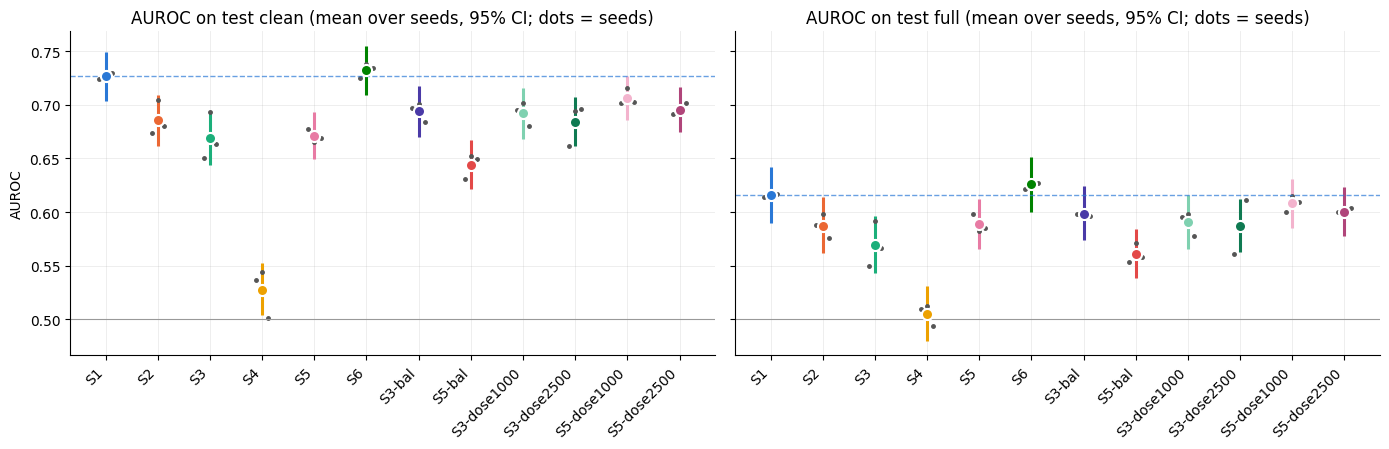

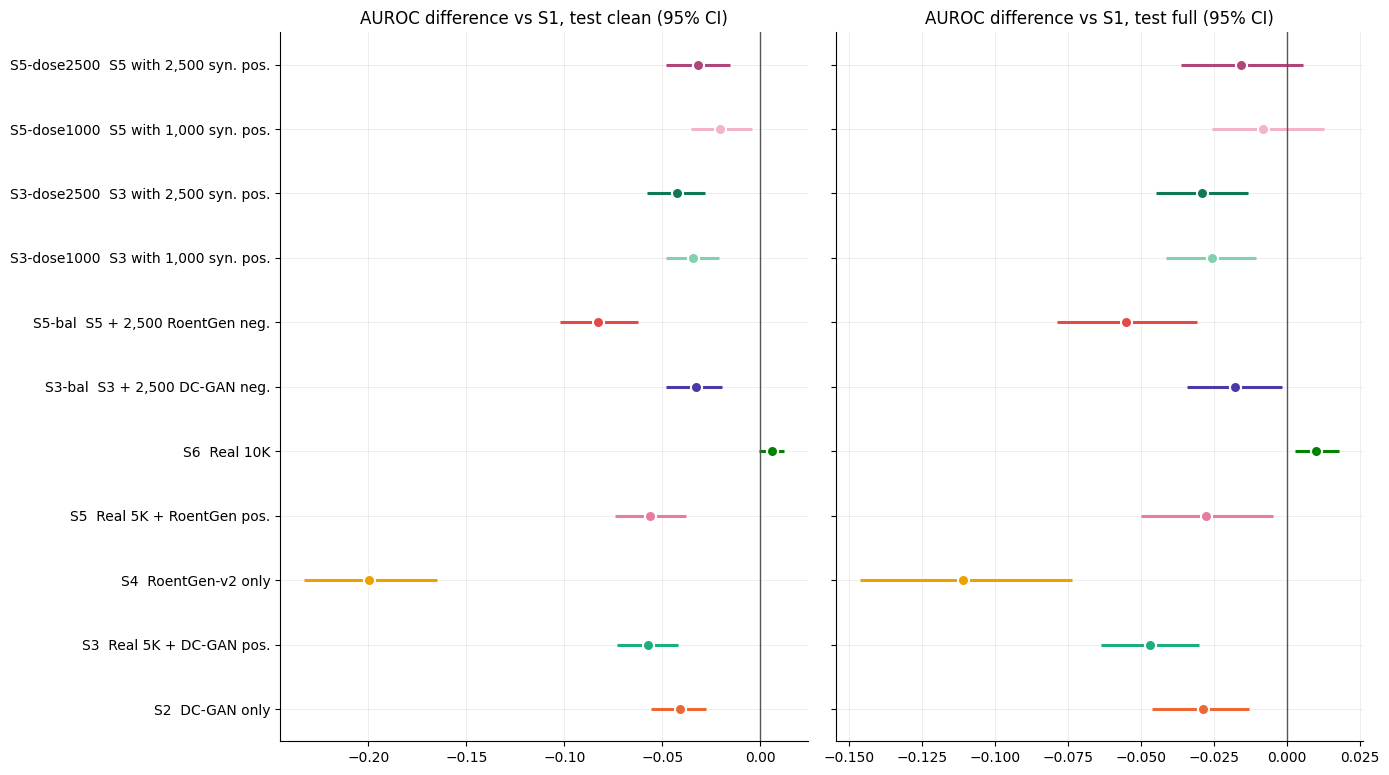

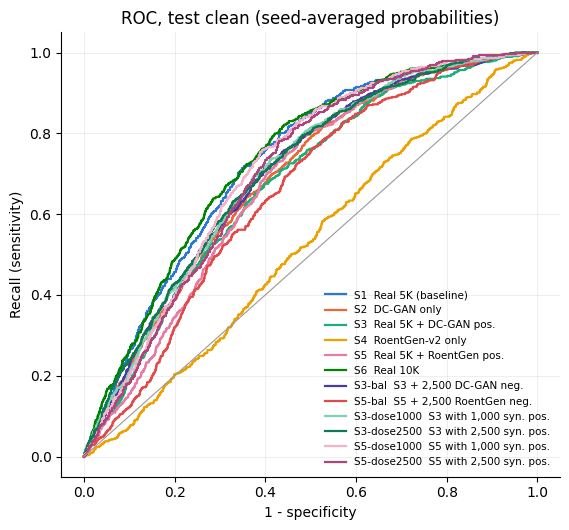

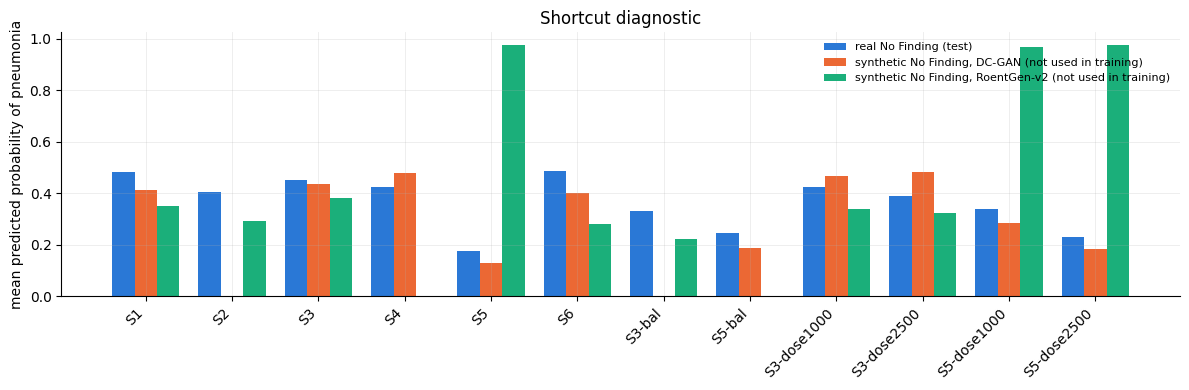

In [9]:
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.6, 'font.size': 10})
col = lambda s: COLORS.get(s, '#7a7a7a')
x = np.arange(len(SCN))

# (1) AUROC per scenario with CI and seed values
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for a_, s in zip(ax, ('clean', 'full')):
    for i, scn in enumerate(SCN):
        pt, lo, hi, _ = agg(scn, s, 'auroc'); a_.vlines(i, lo, hi, color=col(scn), lw=2.2); a_.plot(i, pt, 'o', color=col(scn), ms=8, mec='white', mew=1.5, zorder=3)
        a_.plot(np.full(len(SEEDS[scn]), i) + np.linspace(-0.12, 0.12, len(SEEDS[scn])), R[scn][s]['auroc']['point'], '.', color='#555555', ms=5, zorder=2)
    a_.axhline(agg(REF, s, 'auroc')[0], color=col(REF), lw=1, ls='--', alpha=0.7); a_.axhline(0.5, color='#999999', lw=0.8)
    a_.set_xticks(x); a_.set_xticklabels(SCN, rotation=45, ha='right'); a_.set_title(f'AUROC on test {s} (mean over seeds, 95% CI; dots = seeds)')
ax[0].set_ylabel('AUROC'); plt.tight_layout(); plt.savefig(OUT / 'fig_auroc.png', dpi=150, bbox_inches='tight'); plt.show()

# (2) difference with the baseline
others = [s for s in SCN if s != REF]; fig, ax = plt.subplots(1, 2, figsize=(14, 0.55 * len(others) + 1.8), sharey=True)
for a_, s in zip(ax, ('clean', 'full')):
    for i, scn in enumerate(others):
        d = paired(scn, REF, s, 'auroc'); a_.hlines(i, d[1], d[2], color=col(scn), lw=2.2); a_.plot(d[0], i, 'o', color=col(scn), ms=8, mec='white', mew=1.5, zorder=3)
    a_.axvline(0, color='#555555', lw=1); a_.set_yticks(range(len(others))); a_.set_yticklabels([f'{s_}  {nm(s_)}' for s_ in others]); a_.invert_yaxis(); a_.set_title(f'AUROC difference vs {REF}, test {s} (95% CI)')
plt.tight_layout(); plt.savefig(OUT / 'fig_difference_vs_baseline.png', dpi=150, bbox_inches='tight'); plt.show()

# (3) ROC curves (test clean; probabilities averaged over seeds, for display only)
fig, ax = plt.subplots(figsize=(5.8, 5.4)); m = test.clean.values; y = test.label.values[m]
for scn in SCN:
    p = np.mean([RUNS[(scn, s)]['p'][m] for s in SEEDS[scn]], 0); fpr, tpr, _ = roc_curve(y, p); ax.plot(fpr, tpr, color=col(scn), lw=1.6, label=f'{scn}  {nm(scn)}')
ax.plot([0, 1], [0, 1], color='#999999', lw=0.8); ax.set_xlabel('1 - specificity'); ax.set_ylabel('Recall (sensitivity)'); ax.set_title('ROC, test clean (seed-averaged probabilities)'); ax.legend(fontsize=7.5, frameon=False, loc='lower right')
plt.tight_layout(); plt.savefig(OUT / 'fig_roc.png', dpi=150, bbox_inches='tight'); plt.show()

# (4) shortcut diagnostic
fig, ax = plt.subplots(figsize=(12, 4)); w = 0.26
ax.bar(x - w, sdf.mean_prob_real_neg, w, color='#2a78d6', label='real No Finding (test)'); ax.bar(x, sdf.mean_prob_syn_neg_dcgan, w, color='#eb6834', label='synthetic No Finding, DC-GAN (not used in training)')
ax.bar(x + w, sdf.mean_prob_syn_neg_roentgen, w, color='#1baf7a', label='synthetic No Finding, RoentGen-v2 (not used in training)')
ax.set_xticks(x); ax.set_xticklabels(SCN, rotation=45, ha='right'); ax.set_ylabel('mean predicted probability of pneumonia'); ax.set_title('Shortcut diagnostic'); ax.legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig(OUT / 'fig_shortcut.png', dpi=150, bbox_inches='tight'); plt.show()

### 10. Training Summary

In [10]:
ts = summ.reset_index(); ts = ts[ts.scenario.isin(SCN)].groupby('scenario').agg(seeds=('seed', 'count'), n_train=('n_train', 'first'), n_syn_pos=('n_syn_pos', 'first'), n_syn_neg=('n_syn_neg', 'first'),
                                                                              val_auc=('val_auc', 'mean'), best_epoch=('best_epoch', 'mean'), epochs_run=('epochs_run', 'mean')).reindex(SCN).round(3)
ts.to_csv(OUT / 'training_summary.csv'); print(ts.to_string()); print('\nFiles written to', OUT, ':', sorted(p.name for p in OUT.iterdir()))

             seeds  n_train  n_syn_pos  n_syn_neg  val_auc  best_epoch  epochs_run
scenario                                                                          
S1               3     5000          0          0    0.729       4.000       8.000
S2               3     5000       2500       2500    0.694       2.000       6.000
S3               3    10000       5000          0    0.677       1.000       5.000
S4               3     5000       2500       2500    0.468       5.000       9.000
S5               3    10000       5000          0    0.685      10.667      13.333
S6               3    10000          0          0    0.736       5.333       9.333
S3-bal           3    12500       5000       2500    0.693       4.000       8.000
S5-bal           3    12500       5000       2500    0.662      13.000      14.667
S3-dose1000      3     6000       1000          0    0.692       2.667       6.667
S3-dose2500      3     7500       2500          0    0.686       4.000       8.000
S5-d